# Volume-Mode Tracking & Birth Detection — Controlled Experiments

A per-window volume profile is fragile in two ways. **(1)** Labelling modes by *prominence rank* (`mode_1` = biggest right now) makes the label **swap identity** whenever two nodes' weights cross — `mode_1` teleports between two physical levels. **(2)** There is no notion of a node *forming*: a one-off noise peak is treated like a real new level. A third, subtler issue: a single physical node often **over-segments** into several nearby sub-peaks.

We fix all three and **validate on synthetic data where the modes are known**. Crucially the synthetic price behaves like real price-volume: it **consolidates in a range** (so volume builds up there), then **drifts to another level** and consolidates again — it does *not* teleport bar-to-bar. We control each node's location, birth time, **formation rate**, drift and death, then score tracking RMSE, identity switches and detection latency against ground truth.

## Methods

**Volume profile** (`mr.volume_profile`). Each bar's volume is spread across its `[low, high]` range to build a volume-weighted price sample; a **weighted KDE** (Gaussian, Scott bandwidth) gives the volume-at-price density, and **1-D peaks** (`scipy.find_peaks`, ranked by topological *prominence*) are the candidate modes, each with a width `σ` = FWHM/2.355. (A `gmm` branch — Bayesian/DP Gaussian mixture — is available as a cross-check.)

**Robust mode detection** (the over-segmentation fix). Three knobs: `bw_adjust` scales the KDE bandwidth (>1 smooths, so a single dwell cluster yields **one** peak instead of several sharp sub-peaks — the cure at the source); `min_prom_frac` keeps only peaks taller than that fraction of the max (drops fuzzy *shoulders* — the 'clear spike' filter); `merge_sep` then **fuses adjacent peaks closer than `merge_sep·σ̄`** into one (`_merge_close_modes`). Two Gaussian bumps are only *resolved* when separated by ≳2σ, so anything closer is really one node; the merged node takes a weighted-mean price, summed weight, and a **combined variance** that widens `σ` — that `σ` is the node's **area of uncertainty** (sharp spike → tight band, fuzzy/merged blob → wide band).

**Tracking + birth detection** (`mr.track_modes`). A lightweight multi-object tracker over the per-window modes:
- **Kalman filter per node**, constant-velocity state `[price, drift]` (dt=1): *predict* `x←Fx, P←FPFᵀ+Q` (process-accel std `q`), *update* on the matched detection with measurement noise `r` (defaults to the node's `σ`).
- **Gated nearest-neighbour association**: a detection matches a track only if the normalised innovation `(z−x)²/S ≤ gate` (χ²₁, ≈ (3σ)²=9) **and** within a hard distance cap `|z−x| ≤ gate_abs·σ`; greedy global-nearest assignment. The hard cap is covariance-independent, so a track whose `P` ballooned while *coasting* cannot capture a far-away newborn node (which would otherwise read as a spurious low→high 'drift'). This keeps a stable id through drift *and* through prominence-rank crossings.
- **Confirmation / death**: an unmatched detection seeds a *tentative* track; it is *confirmed* (a **birth**) once it accrues `confirm` hits — rejecting one-off noise. A track *coasts* on a miss and **dies** after `miss_delete` consecutive misses.

**Data generator** (`mode_lab.synth_modes`). A **sticky regime-switching dwell process**: the price stays in one mode for a geometric **dwell** (~20 bars) while mean-reverting around its centre (persistence `phi`) so volume *builds up* there, then switches to another mode (chosen by current weights) and **glides** to the new level over a few bars. Ground truth per bar: each mode's `center`, its target-occupancy `weight`, and `occ` — the mode actually visited (whose trailing-window fraction is the realised volume share the profile sees). 'Detectable' = that occupancy fraction ≥ a floor.

In [1]:
import sys
sys.path[:0] = ['C:\\Users\\SamuelAhou\\Documents\\operator', 'C:\\Users\\SamuelAhou\\Documents\\operator\\research\\mean_reversion']
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import mode_lab as L
from src.signals import mean_reversion as mr
WINDOW = 90
TRACK = dict(confirm=3, q=0.4, miss_delete=10, min_weight=0.13, gate_abs=4.0)
PROF = dict(bw_adjust=1.5, merge_sep=3.0, min_prom_frac=0.10)   # smoothing + merge + clear-spike
DW = dict(dwell=20, phi=0.7)                      # price dwells ~20 bars, glides quickly on a switch
print('setup ok')

setup ok


## Experiment A — stable identity vs the prominence-rank baseline

A **ranging market**: price oscillates between two levels (100 and 112), dwelling at each in turn so both nodes carry volume. As price migrates, the *currently dominant* node flips, so the prominence-`rank 1` label keeps swapping identity (and the inactive level drifts down the ranking). The tracker should instead hold **two stable identities** throughout. The right-hand panel is the whole-sample volume-at-price **distribution** with the merged modes ±σ.

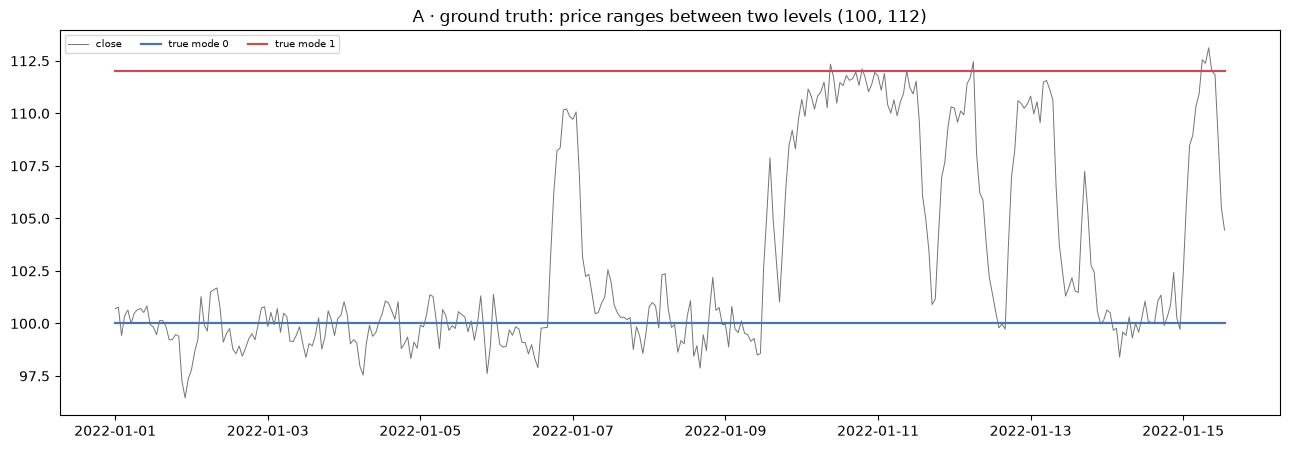

In [2]:
specsA = [dict(center=100.0, w=1.0, sigma=1.2, t_on=0, ramp=1),
          dict(center=112.0, w=1.0, sigma=1.2, t_on=0, ramp=1)]
dfA, truthA = L.synth_modes(specsA, 350, seed=1, **DW)
profA = L.rolling_profiles(dfA, window=WINDOW, step=2, n_modes=3, **PROF)
trkA = mr.track_modes(profA, **TRACK)
baseA = L.baseline_ranks(profA, n_modes=2)
L.plot_truth(dfA, truthA, 'A · ground truth: price ranges between two levels (100, 112)')

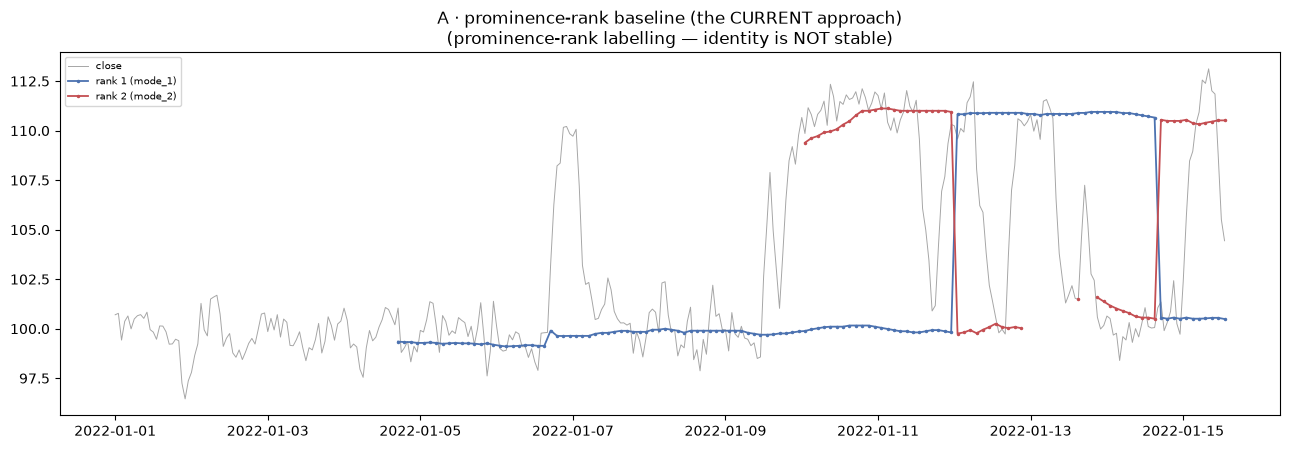

baseline rank-1 identity switches: 2


In [3]:
L.plot_baseline(dfA, baseA, 'A · prominence-rank baseline (the CURRENT approach)')
sw = L.baseline_id_switches(baseA, truthA, rank=1)
print(f'baseline rank-1 identity switches: {sw}')

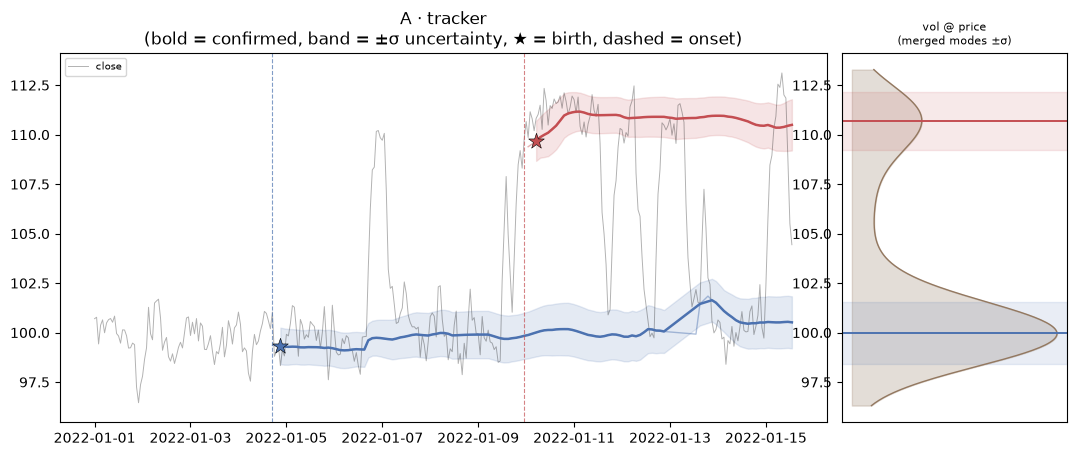

tracker confirmed identities: 2  (expected ~2, each pinned to its level)


In [4]:
L.plot_tracks(dfA, trkA, truthA, 'A · tracker', window=WINDOW, **PROF)
n_conf = trkA[trkA.status == 'confirmed'].track_id.nunique()
print(f'tracker confirmed identities: {n_conf}  (expected ~2, each pinned to its level)')

**Read:** the baseline's rank-1 line swaps identity each time price changes which level it dwells at, and loses the inactive level; the tracker resolves the same data into two clean, persistent tracks with their ±σ uncertainty — both levels stay alive even while price sits at the other. Problem (1) solved: `z_mode_k` is computed against a *track*, not a rank.

## Experiment B — a breakout *birth*, and the over-segmentation fix

Price ranges at **100**; at **t=180** a second level at **113** becomes active and price starts splitting time there, so its volume node builds up (a breakout that holds). First we show the third issue directly: on a late window the **raw** profile splits the lower node into several sub-peaks; the **merge** collapses them to one node with a ±σ band.

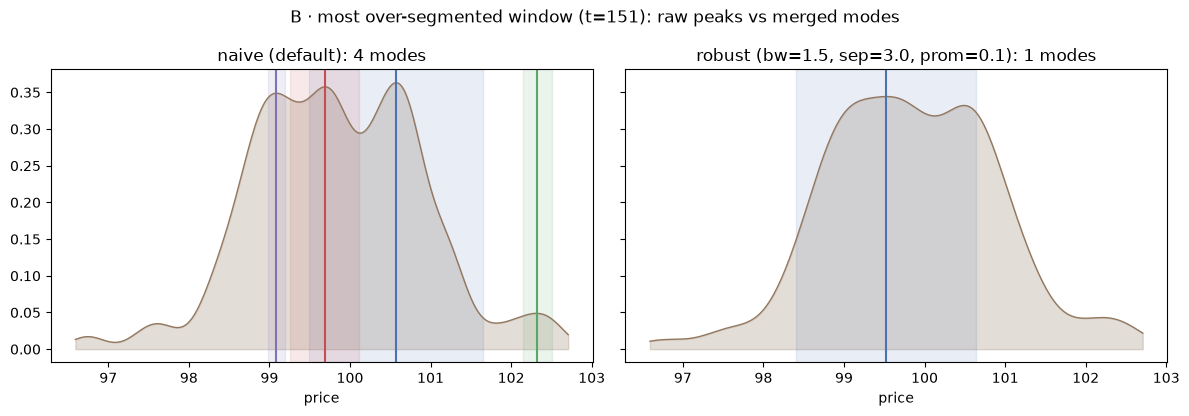

In [5]:
specsB = [dict(center=100.0, w=1.0, sigma=1.2, t_on=0, ramp=1),
          dict(center=113.0, w=1.0, sigma=1.2, t_on=180, ramp=20)]
dfB, truthB = L.synth_modes(specsB, 380, seed=2, **DW)
profB_raw = L.rolling_profiles(dfB, window=WINDOW, step=2, n_modes=4)            # no merge
profB = L.rolling_profiles(dfB, window=WINDOW, step=2, n_modes=4, **PROF)          # robust
# the window where the RAW profile splits the lower node into the most sub-peaks:
tstar = max(profB_raw, key=lambda tm: sum(abs(m['price'] - 100) < 4 for m in tm[1]))[0]
L.plot_merge_demo(dfB.iloc[tstar - WINDOW + 1:tstar + 1],
                  f'B · most over-segmented window (t={tstar}): raw peaks vs merged modes', **PROF)

In [6]:
trkB = mr.track_modes(profB, **TRACK)
def _max_peaks(profs, c0):
    return max(sum(abs(m['price'] - c0) < 4 for m in modes) for _, modes in profs)
print(f'most profile peaks in a single window near the lower node 100 — '
      f'raw: {_max_peaks(profB_raw, 100)}, merged: {_max_peaks(profB, 100)}')

most profile peaks in a single window near the lower node 100 — raw: 4, merged: 1


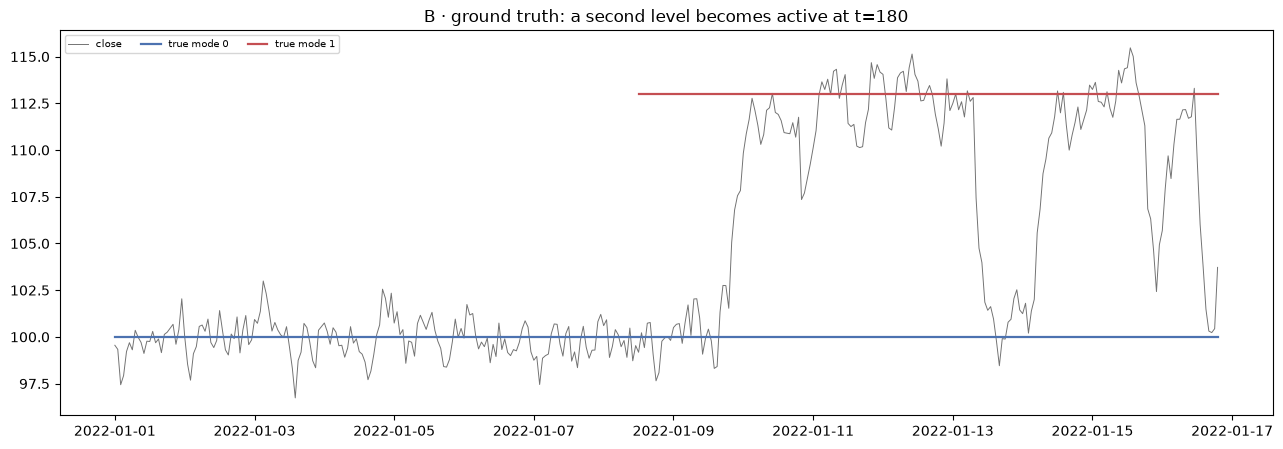

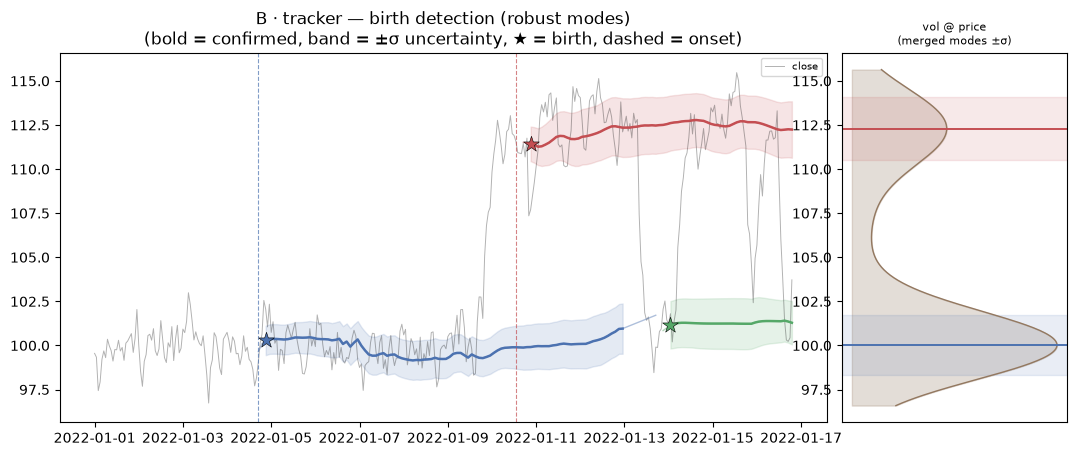

In [7]:
L.plot_truth(dfB, truthB, 'B · ground truth: a second level becomes active at t=180')
L.plot_tracks(dfB, trkB, truthB, 'B · tracker — birth detection (robust modes)', window=WINDOW, **PROF)

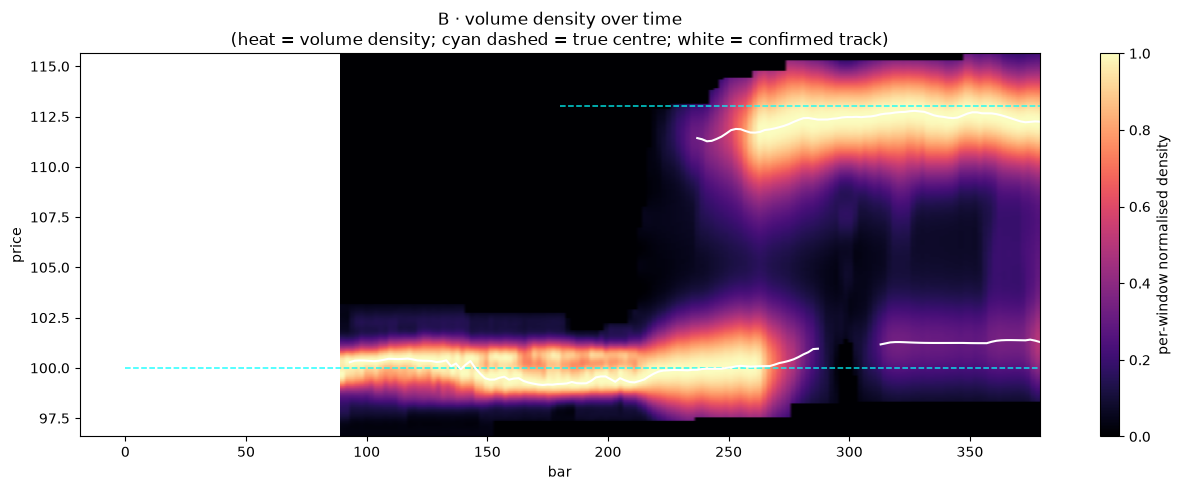

In [8]:
te, gpe, dse = L.rolling_density(dfB, window=WINDOW, step=2, **PROF)
L.plot_heat(dfB, te, gpe, dse, 'B · volume density over time', tracks=trkB, truth=truthB)

In [9]:
lat = L.detection_latency(dfB, trkB, truthB, mode=1, window=WINDOW)
print(f"onset t={lat['onset']}; first detectable in the windowed profile at "
      f"t={lat['detectable']}; confirmed at t={lat['confirmed']}")
print(f"latency beyond what the data allows = {lat['latency_from_detectable']} bars; "
      f"total delay after onset = {lat['latency_from_onset']} bars")

onset t=180; first detectable in the windowed profile at t=229; confirmed at t=237
latency beyond what the data allows = 8 bars; total delay after onset = 57 bars


**Read:** merging collapses the *within-window* split (the demo above: several raw sub-peaks → one node + ±σ band; the peak count near 100 drops accordingly). The birth is confirmed essentially *as soon as* the new level is visible in the trailing-window profile (latency-from-detectable ≈ 0). The heatmap shows volume building at 113 with the white track latching on once the level is real.

*Note — a fixed pathology:* the 113 node is born as its **own fresh track**, not a mis-associated jump of the 100 track. Without the hard `gate_abs` cap, a stale, over-segmented 100 track (covariance inflated while coasting) could grab the distant newborn 113 detection and the connecting line would look like a phantom 100→113 *drift*. The cap + stronger merge (`merge_sep=3`) remove that: the low track stays at 100 and 113 spawns separately.

## Experiment C — detection latency vs formation rate

Same birth, sweeping the **ramp length** (bars to fully form) over several seeds. Faster formation ⇒ the node becomes detectable sooner ⇒ earlier confirmation.

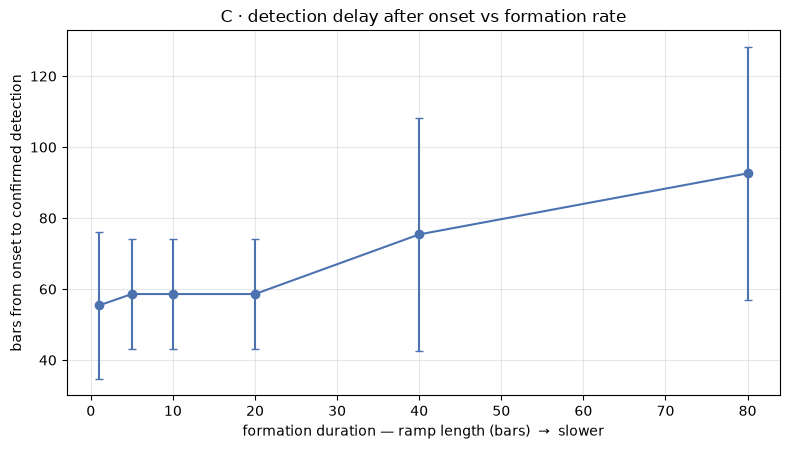

      latency_from_onset  latency_from_detectable
ramp                                             
1                   55.4                      6.2
5                   58.6                      5.6
10                  58.6                      5.6
20                  58.6                      5.6
40                  75.4                      4.6
80                  92.6                      5.4


In [10]:
rows = []
for ramp in (1, 5, 10, 20, 40, 80):
    for seed in range(5):
        sp = [dict(center=100.0, w=1.0, sigma=1.2, t_on=0, ramp=1),
              dict(center=113.0, w=1.0, sigma=1.2, t_on=160, ramp=ramp)]
        d, tr = L.synth_modes(sp, 420, seed=seed, **DW)
        pf = L.rolling_profiles(d, window=WINDOW, step=2, n_modes=3, **PROF)
        tk = mr.track_modes(pf, **TRACK)
        rows.append({'ramp': ramp, 'seed': seed,
                     **L.detection_latency(d, tk, tr, mode=1, window=WINDOW)})
res = pd.DataFrame(rows)
L.plot_latency_vs_rate(res, 'C · detection delay after onset vs formation rate')
print(res.groupby('ramp')[['latency_from_onset', 'latency_from_detectable']].mean().round(1))

**Read:** monotone — a node that forms slowly is confirmed later (it takes longer to dominate the window), while `latency_from_detectable` stays small across rates. The tracker is as prompt as the windowed measurement permits; the rest is physics of accumulation.

## Experiment D — tracking a drifting node

A node whose centre **drifts** (0.05 price/bar) while a second sits static. The constant-velocity track should follow it; the residual is dominated by the trailing window's own lag on a moving target (which the velocity term partly anticipates).

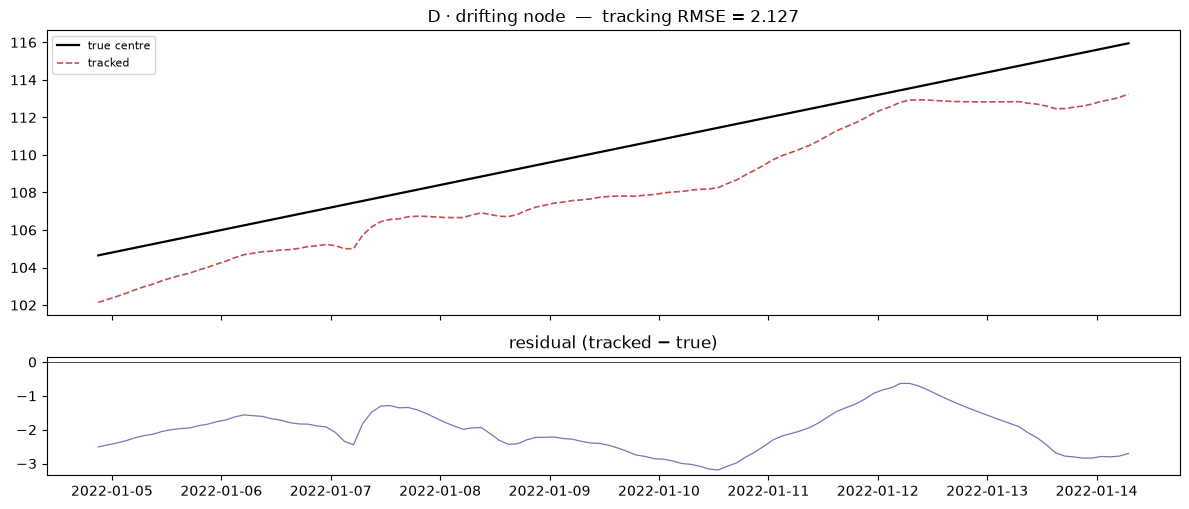

drift tracking RMSE = 2.127 price units


In [11]:
specsD = [dict(center=100.0, w=1.0, sigma=1.0, t_on=0, ramp=1, drift=0.05),
          dict(center=80.0, w=0.8, sigma=1.0, t_on=0, ramp=1)]
dfD, truthD = L.synth_modes(specsD, 320, seed=3, **DW)
profD = L.rolling_profiles(dfD, window=WINDOW, step=2, n_modes=3, **PROF)
trkD = mr.track_modes(profD, **dict(TRACK, q=0.5))
rmse = L.plot_drift(dfD, trkD, truthD, mode=0, title='D · drifting node')
print(f'drift tracking RMSE = {rmse:.3f} price units')

## Experiment E — a realistic regime: a stair-step trend

The lifelike case the whole lab is built for. Price **consolidates at 100**, then **drifts up and consolidates at 107**, then again up to **114** — each level fading as the next forms (a trending market that pauses at successive value areas). This stresses everything at once: sequential births at different *levels and rates*, deaths of the old levels, and identity stability through the migration. The heatmap shows volume building at each step then shifting up.

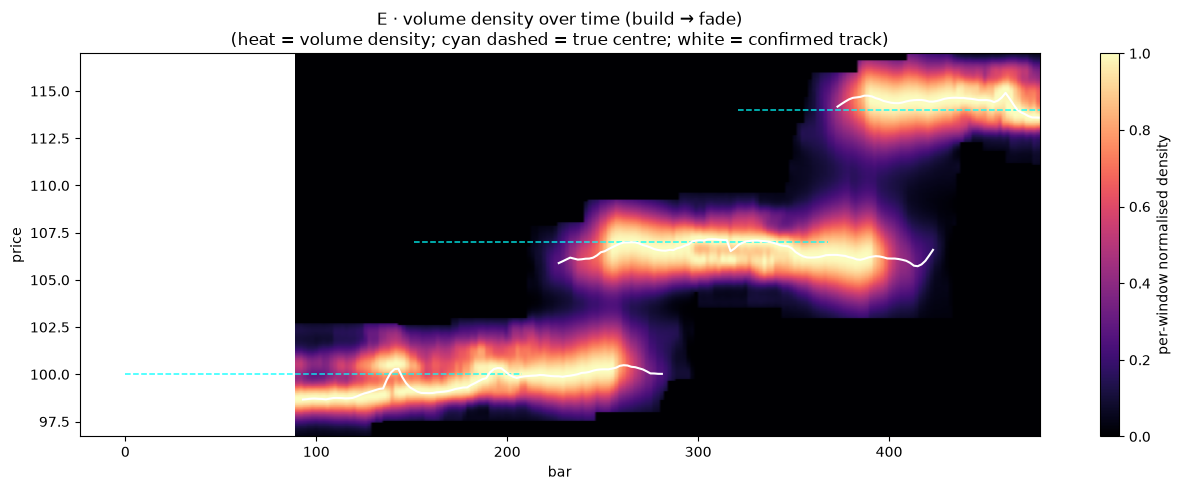

In [12]:
specsE = [dict(center=100.0, w=1.0, sigma=1.2, t_on=0, t_off=210, ramp=1, ramp_off=60),
          dict(center=107.0, w=1.0, sigma=1.2, t_on=150, t_off=370, ramp=50, ramp_off=60),
          dict(center=114.0, w=1.0, sigma=1.2, t_on=320, ramp=50)]
dfE, truthE = L.synth_modes(specsE, 480, seed=5, **DW)
profE = L.rolling_profiles(dfE, window=WINDOW, step=2, n_modes=4, **PROF)
trkE = mr.track_modes(profE, **TRACK)
te, gpe, dse = L.rolling_density(dfE, window=WINDOW, step=2, **PROF)
L.plot_heat(dfE, te, gpe, dse, 'E · volume density over time (build → fade)', tracks=trkE, truth=truthE)

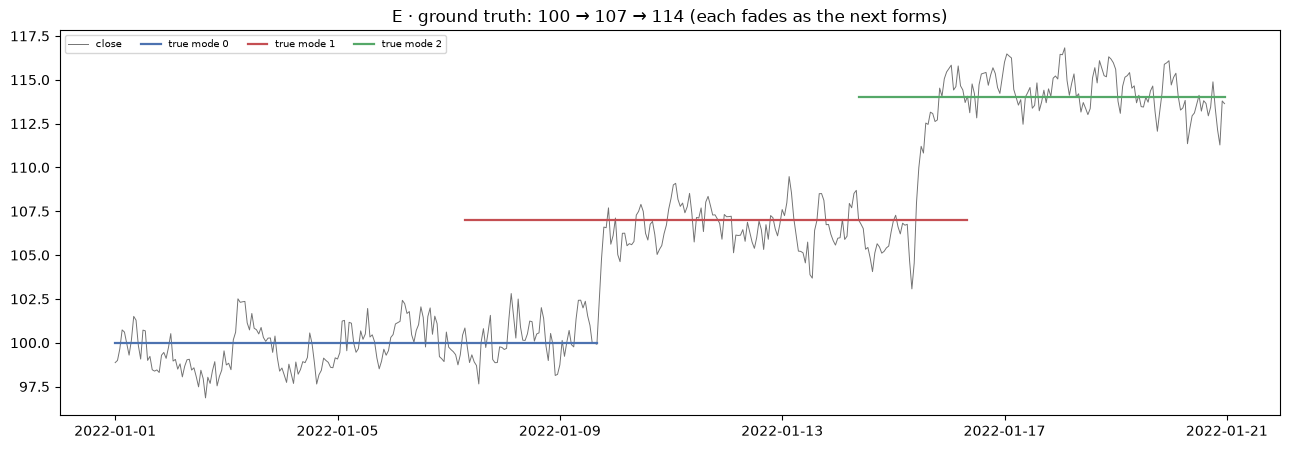

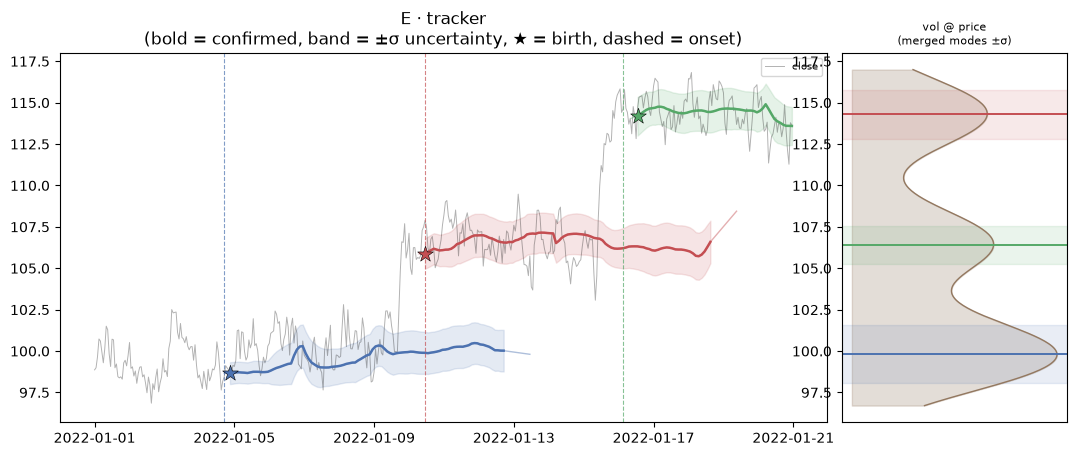

step 107: onset 150, detectable 227, confirmed 227, delay-from-onset 77
step 114: onset 320, detectable 363, confirmed 373, delay-from-onset 53


In [13]:
L.plot_truth(dfE, truthE, 'E · ground truth: 100 → 107 → 114 (each fades as the next forms)')
L.plot_tracks(dfE, trkE, truthE, 'E · tracker', window=WINDOW, **PROF)
for m, name in [(1, 'step 107'), (2, 'step 114')]:
    lat = L.detection_latency(dfE, trkE, truthE, mode=m, window=WINDOW)
    print(f"{name}: onset {lat['onset']}, detectable {lat['detectable']}, "
          f"confirmed {lat['confirmed']}, delay-from-onset {lat['latency_from_onset']}")

**Read:** the heatmap is the picture we were after — volume **builds at each level then shifts up** (a staircase), not a teleporting cloud. The tracker births each step shortly after price starts dwelling there and lets the old level's track die as its volume fades, keeping stable identities through the migration. Each consolidation is now a *single* clean track: the extra KDE smoothing (`bw_adjust`) stops a noisy dwell cluster from breaking into 2–3 simultaneous sub-tracks, and the weight floor (`min_weight`) keeps the brief volume smeared along a transition from confirming a phantom mid-level node.

## Summary

On realistic data (price that consolidates then drifts to new levels) where the modes are known, the robust detector + `mr.track_modes`:
- **(1) keeps a stable identity** — two ranged levels give clean persistent tracks where the prominence-rank label kept swapping and dropping the inactive level;
- **(2) detects births** by confirmation, latching a new level ≈ as soon as price has dwelt there enough to make it visible, and rejecting transient peaks;
- **(3) resists over-segmentation** — the clear-spike filter + proximity merge collapse a split node to one, with a `σ` **uncertainty band** that widens when evidence is fuzzy;
- recovers the **formation rate** (latency rises with ramp length), **follows drift** (RMSE ≈ window lag), and handles a **realistic stair-step trend** (build → drift → build) with births and deaths.

Next: run the same robust detector + tracker on the real-data scenarios (btc 4h) so `z_mode_k` is computed against persistent, identity-stable nodes with explicit uncertainty, rather than per-window prominence ranks.